# Feature extraction using CellProfiler

In this tutorial, we show how to use Squidpy with functions from CellProfiler pipelines for image processing and feature extraction.   

We'll go through the following steps:

1. Load Visium fluorescence data.
2. Segment cells in Squidpy.
3. Calculate CellProfiler's granularity features for image crops of Visium spots.
4. Compute clustering on the image features in Squidpy.

CellProfiler is typically used via its GUI interface to build image processing pipelines.
First, download and install CellProfiler from the [download page](https://github.com/CellProfiler/CellProfiler). Check the issues on [CellProfiler Github](https://github.com/CellProfiler/CellProfiler/issues) in case of installation problems (can be tricky).   

Note: In the future, CellProfiler functions will also be accessible via Python directly (according to the announcements of the CellProfiler team). Since this is not yet publicly well documented, we'll restrict this tutorial to the laborious way of saving intermediate files to bridge Squidpy and CellProfiler. For information on how to use the `cellprofiler-core` package for Python integration, the following [link](https://github.com/CellProfiler/CellProfiler/wiki/CellProfiler-as-a-Python-package) might be helpful.   

## Import packages & data

In [13]:
import itertools
from pathlib import Path

from PIL import Image

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

import anndata as ad
import scanpy as sc
import squidpy as sq

sc.logging.print_header()
print(f"squidpy=={sq.__version__}")
sc.set_figure_params(facecolor="white", figsize=(8, 8))

# load the pre-processed dataset
img = sq.datasets.visium_fluo_image_crop()
adata = sq.datasets.visium_fluo_adata_crop()

scanpy==1.9.1 anndata==0.8.0 umap==0.5.3 numpy==1.21.6 scipy==1.8.0 pandas==1.4.2 scikit-learn==1.0.2 statsmodels==0.13.2 python-igraph==0.9.9 pynndescent==0.5.6
squidpy==1.2.2


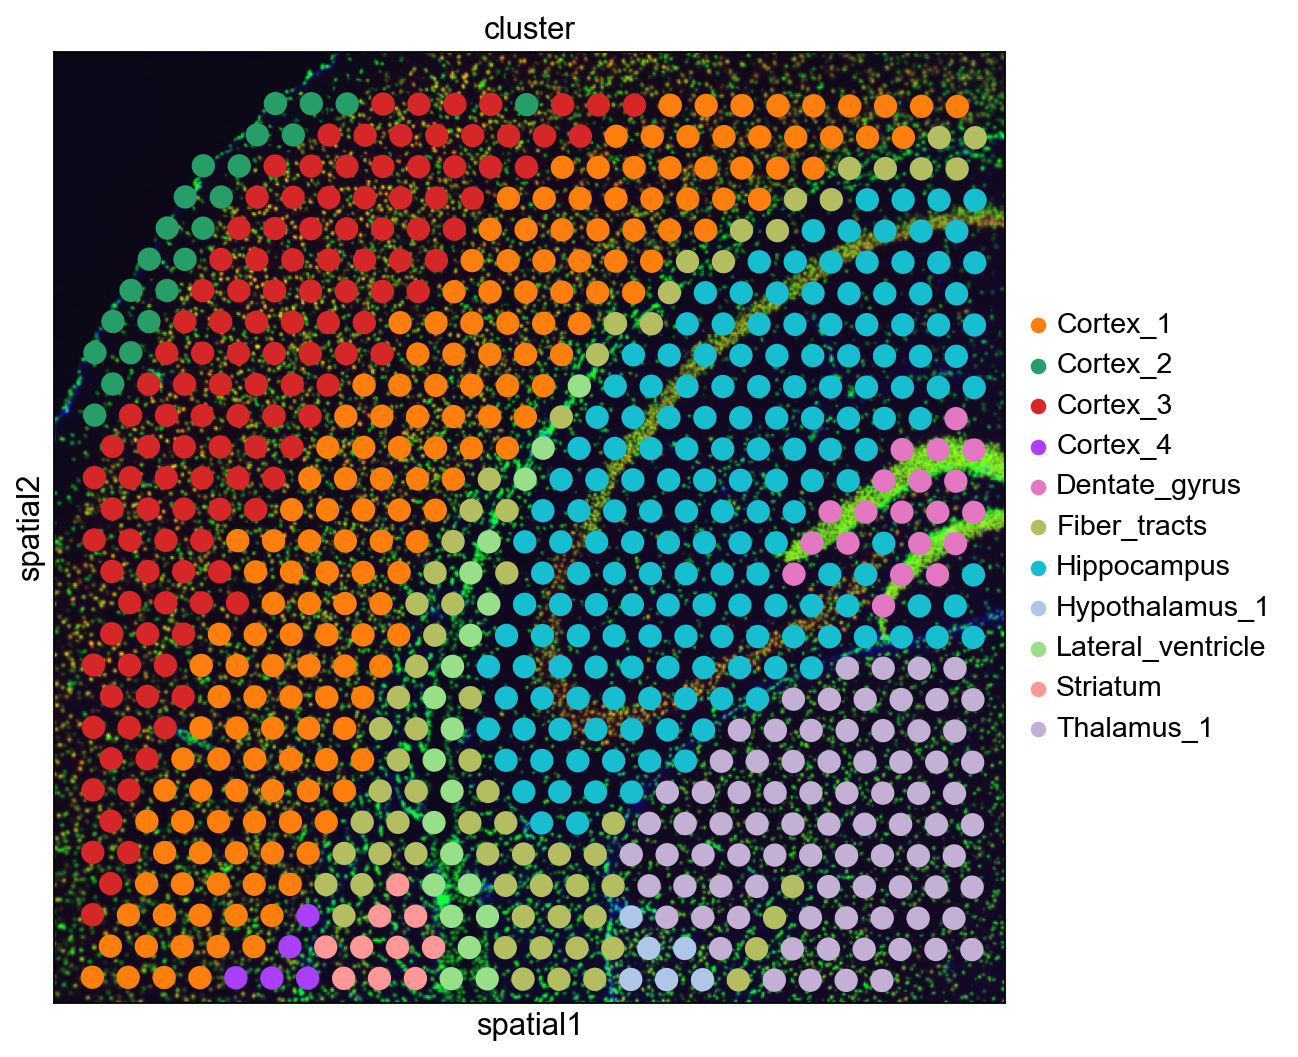

In [14]:
sq.pl.spatial_scatter(adata, color="cluster")

## Setup files
Create some arbitrary empty base directory `BASE_DIR` and a folder `imgs_dir = BASE_DIR + "tmp_imgs"` in it.

In [15]:
BASE_DIR = "./squidpy_tutorial_cellprofiler/"
imgs_dir = BASE_DIR + "tmp_imgs/"
Path(imgs_dir).mkdir(parents=True, exist_ok=True)

## Image segmentation

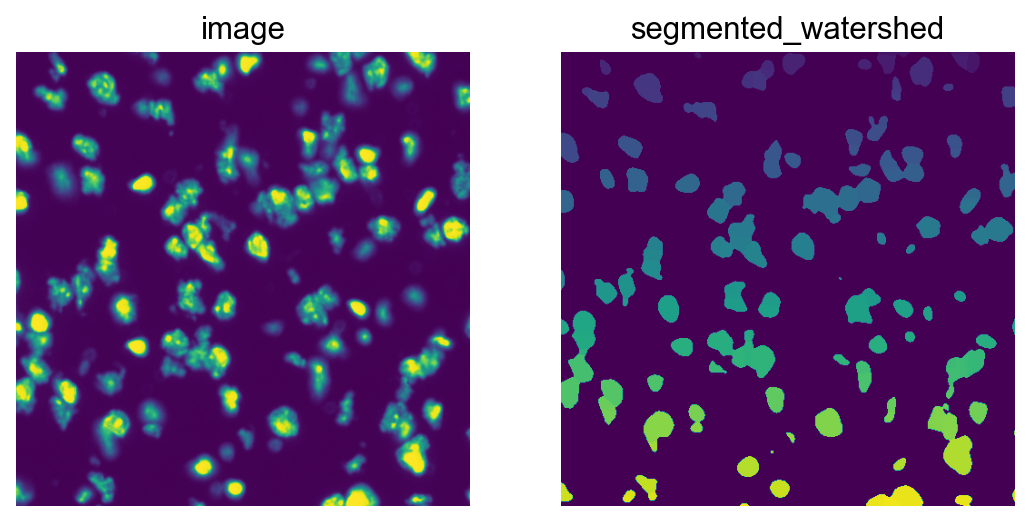

In [16]:
sq.im.process(
    img=img,
    layer="image",
    method="smooth",
    sigma=[2, 2, 0, 0],
)

sq.im.segment(
    img=img, layer="image_smooth", method="watershed", channel_ids=0, chunks=1000
)

# plot the resulting segmentation
fig, ax = plt.subplots(1, 2)
img_crop = img.crop_corner(2000, 2000, size=500)
img_crop.show(layer="image", channel=0, ax=ax[0])
img_crop.show(
    layer="segmented_watershed",
    channel=0,
    ax=ax[1],
)

## Save image crops and segmentations
For each Visium spot we generate crops:

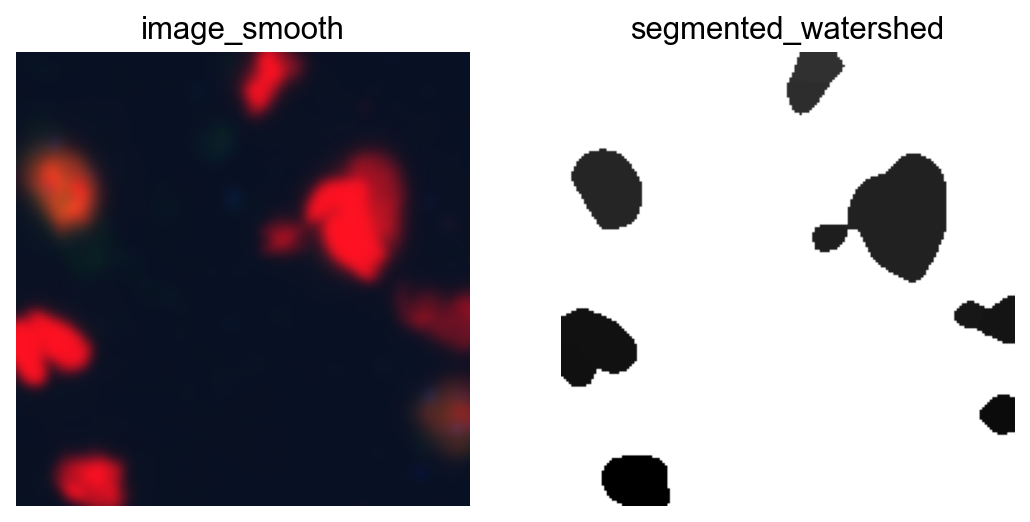

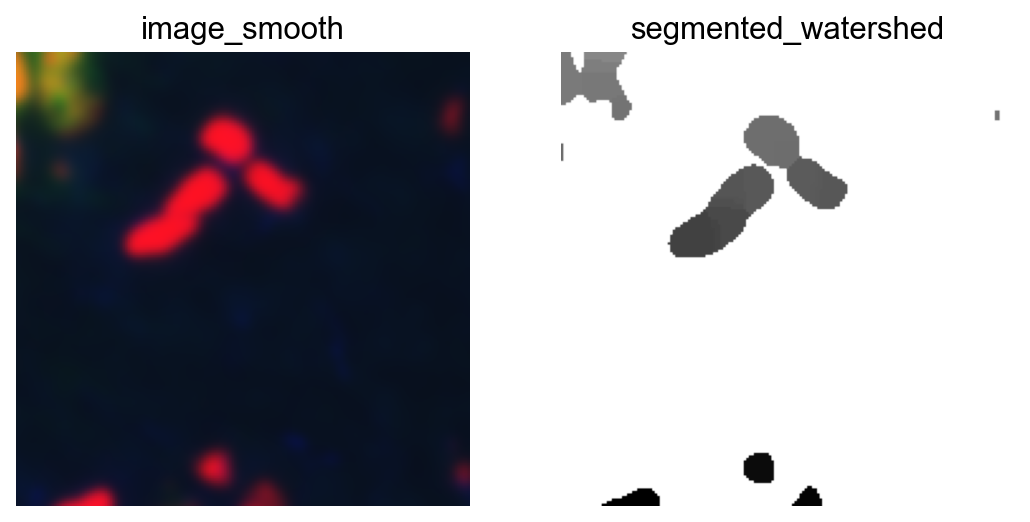

In [17]:
for crop, obs in itertools.islice(
    img.generate_spot_crops(
        adata, obs_names=adata.obs_names, return_obs=True, as_array=False
    ),
    2,
):
    fig, axes = plt.subplots(1, 2)
    crop.show("image_smooth", ax=axes[0])
    crop.show("segmented_watershed", ax=axes[1], cmap="Greys")
    plt.show()

Save the fluorescence image and the segmentations of each crop.

In [24]:
for crop, obs in img.generate_spot_crops(
    adata, obs_names=adata.obs_names, return_obs=True, as_array=False
):
    Image.fromarray(
        (np.array(crop["image_smooth"]) * 255).squeeze().astype(np.uint8)
    ).save(imgs_dir + f"image_{obs}.png")
    Image.fromarray((np.array(crop["segmented_watershed"][:, :, 0])).squeeze()).save(
        imgs_dir + f"segments_{obs}.tif"
    )

## CellProfiler Pipeline: Calculate Image Features

### 1. Open the CellProfiler GUI App. A new project should open automatically.
![image1](tutorial_cellprofiler_images/01CP_new_project.png)

### 2. Save the project in `BASE_DIR`.
![image2](tutorial_cellprofiler_images/02CP_save_project.png)

### 3. CP-Pipeline `Images`: Drag and Drop the folder `imgs_dir` into CellProfiler.
![image3](tutorial_cellprofiler_images/03CP_import_images.png)

### 4. CP-Pipeline `NamesAndTypes`: Declare to load crops as color images and segmentations as objects. Crops and segmentations files are aligned automatically.
![image4](tutorial_cellprofiler_images/04CP_NamesAndTypes.png)

### 5. Convert image crops to gray images: Add `ColorToGray` module and define parameters.
![image5](tutorial_cellprofiler_images/05CP_Create_ColorToGray.png)
![image6](tutorial_cellprofiler_images/06CP_ColorToGray.png)

### 6. Measure CellProfiler's Granularity features within segments for each crop: Add `MeasureGranularity` module and define parameters.
![image7](tutorial_cellprofiler_images/07CP_Create_Granularity.png)
![image8](tutorial_cellprofiler_images/08CP_Granularity.png)

### 7. Export results to csv.
![image9](tutorial_cellprofiler_images/09CP_Create_Export.png)   
![image10](tutorial_cellprofiler_images/10CP_Export.png)

### 8. Run CellProfiler Pipeline (takes several minutes).
![image11](tutorial_cellprofiler_images/11CP_Run.png)

You can now delete the images in `imgs_dir` by uncommenting the cell below:

In [ ]:
# !rm -rf $imgs_dir

## Cluster features
Load CellProfiler output of Granularity features of each Visium spot and rearrange the output for `adata.obsm`.

In [25]:
# load CellProfiler output
df = pd.read_csv(BASE_DIR + "/squidpy_Image.csv")
# set obs names as index
df.index = df["FileName_Spot_Crop"].apply(lambda s: s.split("_")[1].split(".")[0])
df.index.name = "obs"
# Get the measured Granularity features and rename them
features = [
    f"{stat}_Segments_Granularity_{i}_SpotGray"
    for stat in ["Mean", "StDev"]
    for i in range(1, 17)
]
df = df[features]
df.columns = [s.split("_")[0] + s.split("_")[2] + s.split("_")[3] for s in df.columns]

In [26]:
df.head()

,MeanGranularity1,MeanGranularity2,MeanGranularity3,MeanGranularity4,MeanGranularity5,MeanGranularity6,MeanGranularity7,MeanGranularity8,MeanGranularity9,MeanGranularity10,...,StDevGranularity7,StDevGranularity8,StDevGranularity9,StDevGranularity10,StDevGranularity11,StDevGranularity12,StDevGranularity13,StDevGranularity14,StDevGranularity15,StDevGranularity16
obs,,,,,,,,,,,,,,,,,,,,,
AAACGAGACGGTTGAT-1,35.513010,8.562676,26.546550,14.187602,7.629247,3.334912,2.057867,0.623025,0.258596,0.336359,...,1.615079,0.490024,0.284772,0.251887,0.000000,0.000000,0.000000,0.196002,0.000000,0.0
AAAGGGATGTAGCAAG-1,34.115594,24.218906,20.290728,4.457829,0.832083,4.670038,3.027418,1.872175,0.694657,0.642282,...,4.840615,2.934531,1.024722,1.045698,0.174283,0.783332,0.156181,0.156181,0.156181,0.0
AAATGGCATGTCTTGT-1,35.680015,15.708321,15.551889,8.760072,5.392920,7.575340,5.474114,0.876559,0.121634,0.000000,...,2.082841,1.640197,0.227598,0.000000,0.392862,0.785725,1.172769,0.234967,0.000000,0.0
AAATGGTCAATGTGCC-1,27.243626,6.490712,9.602902,3.852946,3.829664,0.000000,0.000000,7.289044,8.814914,12.036803,...,0.000000,9.020724,6.604276,3.711367,1.988622,1.063700,0.303914,0.075979,0.151957,0.0
AAATTAACGGGTAGCT-1,33.575662,12.159623,21.226989,19.807115,8.313644,2.021116,0.463706,0.716149,0.283679,0.283679,...,0.328582,0.264752,0.219188,0.219188,0.000000,0.000000,0.219188,0.000000,0.000000,0.0


Load image features into `adata.obsm["features"]` and compute Leiden clustering.

/var/folders/pz/fw_kwtn10t52fps52c0jxm940000gn/T/ipykernel_8107/2650860513.py:5: FutureWarning: X.dtype being converted to np.float32 from float64. In the next version of anndata (0.9) conversion will not be automatic. Pass dtype explicitly to avoid this warning. Pass `AnnData(X, dtype=X.dtype, ...)` to get the future behavour.
  adata = ad.AnnData(features)


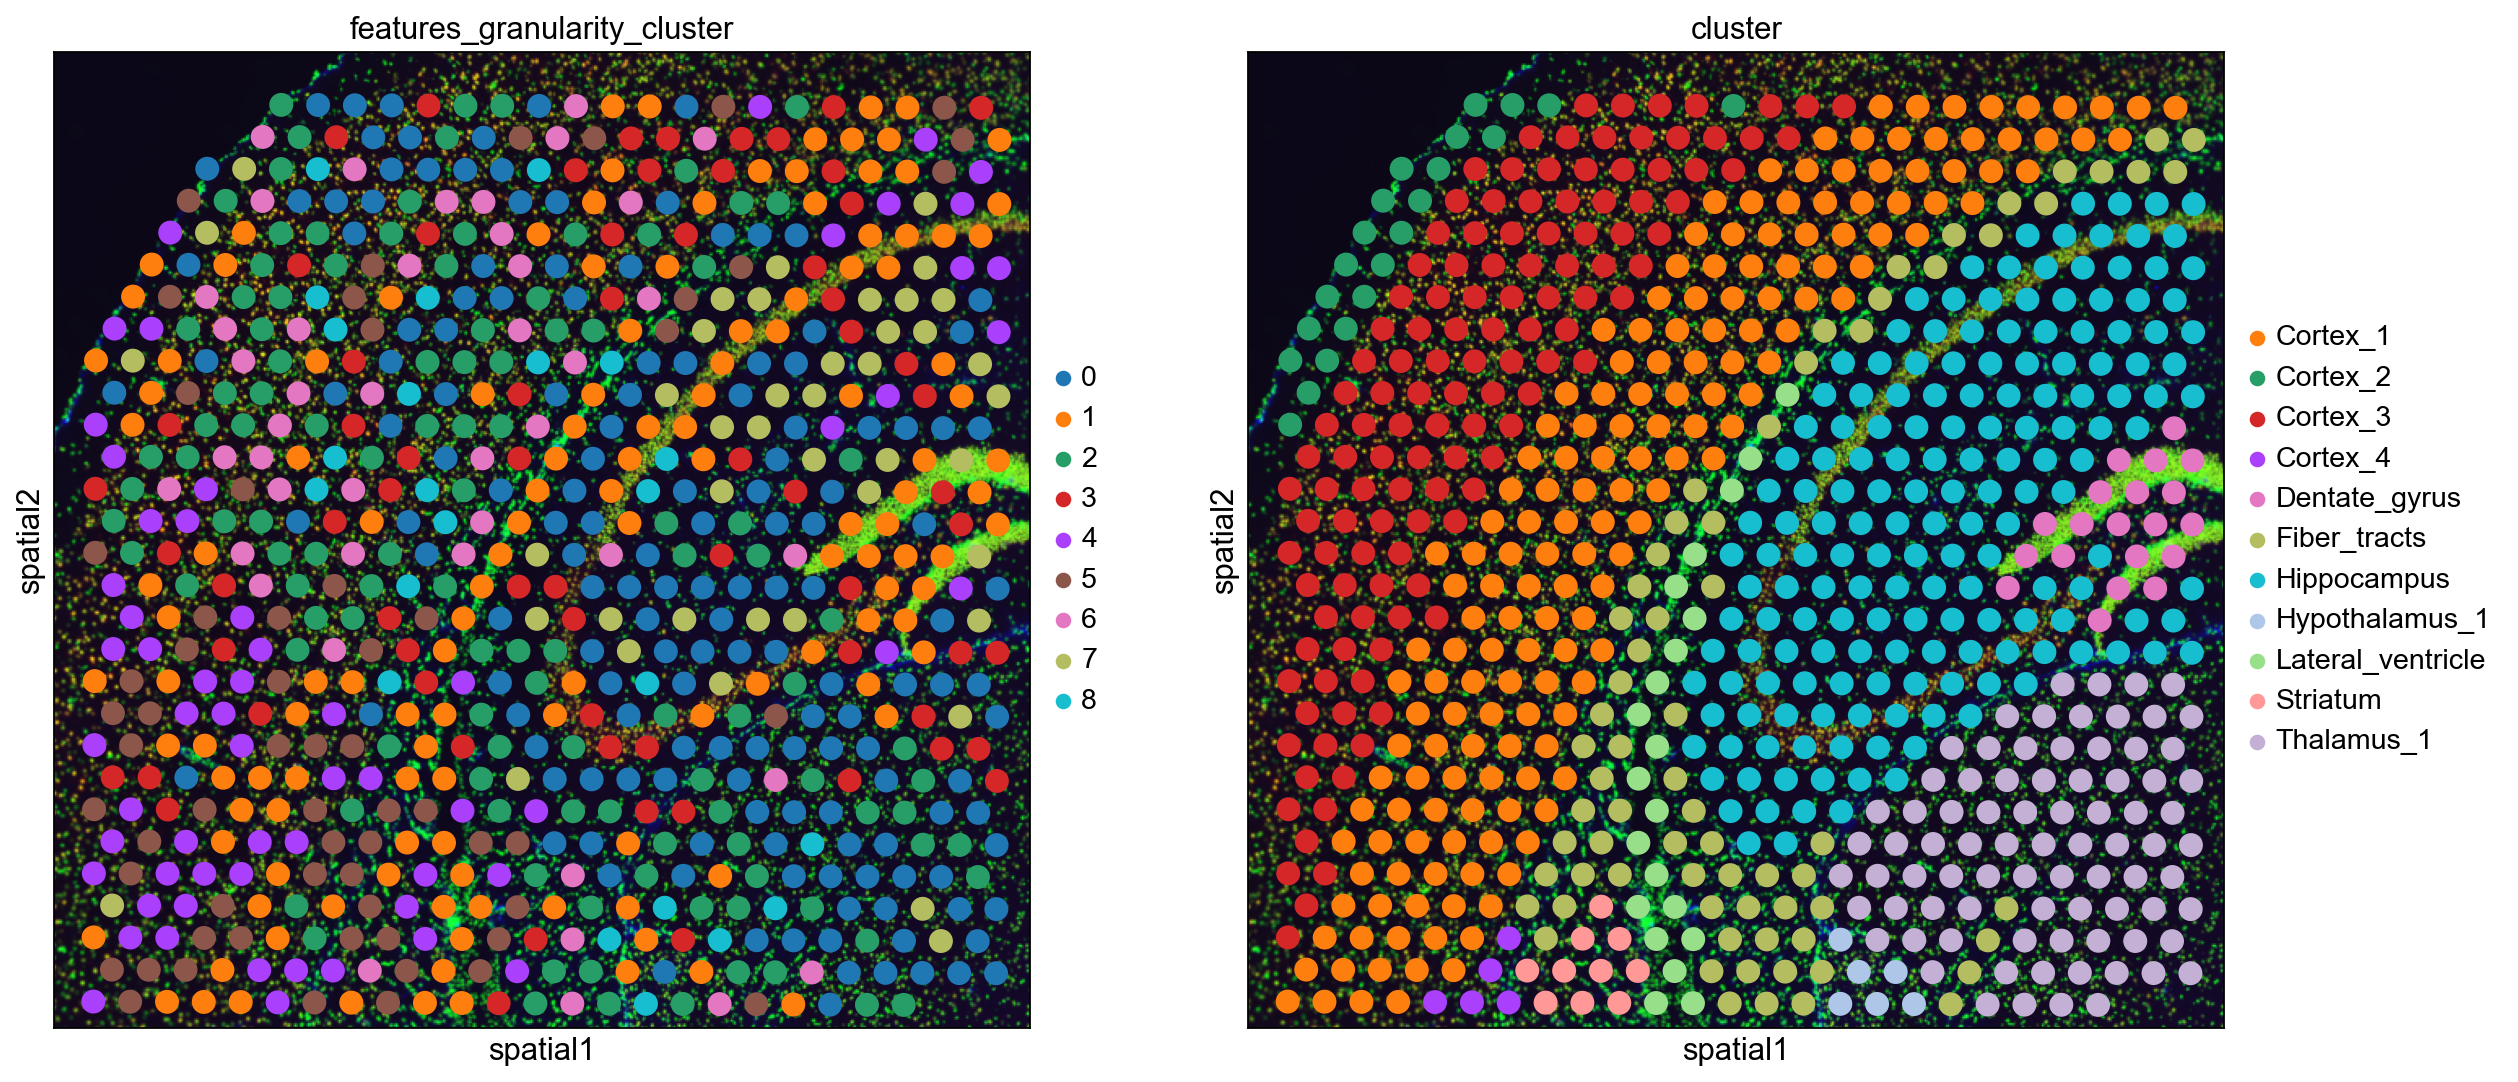

In [27]:
def cluster_features(features: pd.DataFrame):
    """Calculate leiden clustering of features."""
    # create temporary adata to calculate the clustering
    adata = ad.AnnData(features)
    # important - feature values are not scaled, so need to scale them before PCA
    sc.pp.scale(adata)
    # calculate leiden clustering
    sc.pp.pca(adata, n_comps=min(10, features.shape[1] - 1))
    sc.pp.neighbors(adata)
    sc.tl.leiden(adata)

    return adata.obs["leiden"]


# Save feature in adata.obsm
adata.obsm["features"] = df.loc[adata.obs_names].copy()

# Calculate leiden clustering
adata.obs["features_granularity_cluster"] = cluster_features(adata.obsm["features"])

# Plot clusterings
sq.pl.spatial_scatter(
    adata,
    color=[
        "features_granularity_cluster",
        "cluster",
    ],
    ncols=2,
)

We see that e.g. the blue cluster is prominent in the Hippocampus and the Thalamus, and the brown cluster is prominent in dense regions like Dentate gyrus.   

This tutorial is an example on how to integrate CellProfiler within Squidpy pipelines. You can adapt this scheme to other task distributions: e.g. segmentation with CellProfiler and image feature calculation in Squidpy, or process images with CellProfiler, followed by a Squidpy pipeline etc.